In [1]:
import numpy as np
import pandas as pd

In [2]:
def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


A1, L1 = load_mean_adj(
    './result/wo_layer/stage1/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './result/wo_layer/stage2/tuning/bs32_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './result/wo_layer/stage3/tuning/bs32_dp0.1_sw0.5/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)


## 1. Validation

In [3]:
def classify_pairs(adjA, adjB, labels, nameA="A", nameB="B"):
    n = adjA.shape[0]

    # sign(A) * sign(B) = -1 
    signA = np.sign(adjA)
    signB = np.sign(adjB)

    flip_mask = (signA * signB == -1)

    flip_pairs = []
    for i in range(n):
        for j in range(n):
            if flip_mask[i, j]:
                flip_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_flip = pd.DataFrame(flip_pairs)

    same_mask = (signA * signB == 1) & (signA != 0)

    same_pairs = []
    for i in range(n):
        for j in range(n):
            if same_mask[i, j]:
                same_pairs.append({
                    "source": labels[i],
                    "target": labels[j],
                    f"{nameA}_weight": adjA[i, j],
                    f"{nameB}_weight": adjB[i, j],
                    "difference": adjA[i, j] - adjB[i, j]
                })

    df_same = pd.DataFrame(same_pairs)

    return df_flip, df_same

df_12_flip, df_12_same = classify_pairs(A1, A2, L1, nameA="A1", nameB="A2")
df_13_flip, df_13_same = classify_pairs(A1, A3, L1, nameA="A1", nameB="A3")
df_23_flip, df_23_same = classify_pairs(A2, A3, L2, nameA="A2", nameB="A3")

In [4]:
def evaluate_source_plasticity(df_flip, df_same, A1=None, A2=None, labels=None, nameA="A", nameB="B"):
    all_sources = pd.concat([df_flip, df_same])["source"].unique()
    results = []

    if A1 is not None and A2 is not None and labels is not None:
        label_to_idx = {lab: i for i, lab in enumerate(labels)}

        # Precompute norms & dot products for NCC
        dot = np.sum(A1 * A2, axis=1)
        norm1 = np.linalg.norm(A1, axis=1)
        norm2 = np.linalg.norm(A2, axis=1)
        cos_sim = np.divide(dot, norm1 * norm2, out=np.zeros_like(dot), where=(norm1 * norm2) != 0)
        NCC_all = 1 - cos_sim  # full vector

        # Precompute WSFR
        sign1 = np.sign(A1)
        sign2 = np.sign(A2)
        flip_mask_mat = (sign1 * sign2 == -1)
        A1 = A1.copy()
        A2 = A2.copy()
        np.fill_diagonal(A1, 0)
        np.fill_diagonal(A2, 0)
        delta = np.abs(A1 - A2)

        # numerator, denominator for each source node
        #WSFR_num = np.sum(delta * flip_mask_mat, axis=1)
        WSFR_num = 2 * np.sum(
            np.minimum(np.abs(A1), np.abs(A2)) * flip_mask_mat,
            axis=1
        )
        WSFR_denom = np.sum(np.abs(A1) + np.abs(A2), axis=1)
        WSFR_all = np.divide(WSFR_num, WSFR_denom,
                             out=np.zeros_like(WSFR_num),
                             where=WSFR_denom != 0)
    else:
        NCC_all = None
        WSFR_all = None

    # ================= main loop ==================
    for s in all_sources:

        df_flip_s = df_flip[df_flip["source"] == s]
        df_same_s = df_same[df_same["source"] == s]

        flip_count = len(df_flip_s)
        same_count = len(df_same_s)
        total = flip_count + same_count

        # ---------- NRB ----------
        if flip_count > 0:
            flip_to_exc = (df_flip_s[f"{nameA}_weight"] < 0) & (df_flip_s[f"{nameB}_weight"] > 0)
            flip_to_inh = (df_flip_s[f"{nameA}_weight"] > 0) & (df_flip_s[f"{nameB}_weight"] < 0)
            num_exc = flip_to_exc.sum()
            num_inh = flip_to_inh.sum()
        else:
            num_exc = num_inh = 0

        # ---------- Flip Strength ----------
        if flip_count > 0:
            flip_strength = np.mean(np.abs(df_flip_s[f"{nameA}_weight"] - df_flip_s[f"{nameB}_weight"]))
        else:
            flip_strength = 0

        # ---------- NCC & WSFR ----------
        if NCC_all is not None:
            idx = label_to_idx[s]
            NCC = NCC_all[idx]
            WSFR = WSFR_all[idx]
        else:
            NCC = None
            WSFR = None

        results.append({
            "source": s,
            "flip_count": flip_count,
            "same_count": same_count,
            "total_nonzero": total,
            "SFR": flip_count / total if total > 0 else 0,
            "SSR": same_count / total if total > 0 else 0,
            "NRB": num_exc - num_inh,
            "FlipStrength": flip_strength,
            "WSFR": WSFR,
            "NCC": NCC
        })

    return pd.DataFrame(results).sort_values("SFR", ascending=False)




df_source_12 = evaluate_source_plasticity(
    df_12_flip, df_12_same,
    A1=A1, A2=A2, labels=L1,
    nameA="A1", nameB="A2"
)
df_source_13 = evaluate_source_plasticity(
    df_13_flip, df_13_same,
    A1=A1, A2=A3, labels=L1,
    nameA="A1", nameB="A3"
)
df_source_23 = evaluate_source_plasticity(
    df_23_flip, df_23_same,
    A1=A2, A2=A3, labels=L2,
    nameA="A2", nameB="A3"
)

In [5]:
df_source_12

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC
49,IAD,2,1,3,0.666667,0.333333,2,0.432189,0.215452,0.534602
43,PoT,2,3,5,0.400000,0.600000,0,0.408265,0.223646,0.486223
19,VISli,3,5,8,0.375000,0.625000,-3,0.358109,0.319410,0.448891
51,MD,4,7,11,0.363636,0.636364,-2,0.394503,0.162789,0.237679
35,EPd,3,6,9,0.333333,0.666667,-3,0.447346,0.215850,0.210627
...,...,...,...,...,...,...,...,...,...,...
62,CA1,0,3,3,0.000000,1.000000,0,0.000000,0.000000,0.039844
63,PAR,0,1,1,0.000000,1.000000,0,0.000000,0.000000,0.000000
72,PVT,0,6,6,0.000000,1.000000,0,0.000000,0.000000,0.216207
73,PSV,0,3,3,0.000000,1.000000,0,0.000000,0.000000,0.001829


In [6]:
import nrrd
from iblatlas.regions import BrainRegions

df_nt = pd.read_csv("../../transcriptome/merfish/neurotransmitter_fraction.csv",index_col=0)

annotation, _ = nrrd.read("../../ccf-v3/annotation_25.nrrd")
ids, counts = np.unique(annotation, return_counts=True)

volume = pd.DataFrame({
    "atlas_id": ids,
    "volume": counts * 25**3 / 1e9
})

df_nt["atlas_id"] = df_nt["atlas_id"].abs().astype(int)

voxel_volume = 25**3 / 1e9

volume_dict = {
    int(i): c * voxel_volume
    for i, c in zip(ids, counts)
    if i != 0
}

br = BrainRegions()

parent_to_children = {}

for child, parent in zip(
    np.abs(br.id),
    np.abs(br.parent)
):

    if np.isnan(child) or np.isnan(parent):
        continue

    parent_to_children.setdefault(int(parent),[]).append(int(child))


def get_descendants(region_id):

    children = parent_to_children.get(region_id,[])

    if len(children) == 0:
        return [region_id]

    leaves = []

    for child in children:
        leaves.extend(get_descendants(child))

    return leaves


def get_volume(region_id):
    if region_id in volume_dict:
        return volume_dict[region_id]

    leaf_ids = get_descendants(region_id)

    return sum(volume_dict.get(leaf_id,0) for leaf_id in leaf_ids)

df_nt["volume"] = (df_nt["atlas_id"].apply(get_volume))

df_nt

,Chol,Dopa,GABA,GABA-Glyc,Glut,Glut-GABA,Nora,Sero,cell_number,atlas_id,volume
AAA,0.026902,0.0,0.736864,0.000420,0.231610,0.004203,0.0,0.0,4803,23,0.494563
ACAd,0.000000,0.0,0.118460,0.000000,0.880990,0.000550,0.0,0.0,21159,39,6.259563
ACAv,0.000000,0.0,0.091720,0.000000,0.907890,0.000390,0.0,0.0,24178,48,4.820094
ACB,0.007831,0.0,0.986176,0.000000,0.004522,0.001471,0.0,0.0,34652,56,4.398266
AId,0.000000,0.0,0.132951,0.000000,0.866645,0.000404,0.0,0.0,18153,104,7.452687
...,...,...,...,...,...,...,...,...,...,...,...
VM,0.000000,0.0,0.040731,0.000522,0.958747,0.000000,0.0,0.0,4401,685,0.926547
VPL,0.000000,0.0,0.055556,0.000000,0.944444,0.000000,0.0,0.0,4750,718,0.876734
VPLpc,0.000000,0.0,0.017182,0.000000,0.982818,0.000000,0.0,0.0,548,725,0.098844
VPM,0.000000,0.0,0.005398,0.000000,0.994602,0.000000,0.0,0.0,10820,733,1.644719


In [7]:
def calculate_category_proportions(row):
    excitatory_sum = sum([row[col] for col in ["Glut"] if row[col] > 0])
    inhibitory_sum = sum([row[col] for col in ["GABA-Glyc", "GABA"] if row[col] > 0])
    modulatory_sum = sum([row[col] for col in ["Chol", "Dopa", "Nora", "Sero", "Glut-GABA"] if row[col] > 0])

    total = excitatory_sum + inhibitory_sum + modulatory_sum
    if total == 0: 
        return {"Excitatory": 0, "Inhibitory": 0, "Modulatory": 0}
    
    return {
        "Excitatory": excitatory_sum / total,
        "Inhibitory": inhibitory_sum / total,
        "Modulatory": modulatory_sum / total
    }

def calculate_non_dominance_std(row):

    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    return np.std(proportions)

def calculate_non_dominance_max(row):
    p_exc = row["Excitatory"] 
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    return 1 - max(p_exc+p_mod, p_inh+p_mod)

def calculate_dominance_max(row, exc_weight=1, inh_weight=1.1):
    p_exc = row["Excitatory"] * exc_weight  
    p_inh = row["Inhibitory"] * inh_weight  
    p_mod = row["Modulatory"]

    return max(p_exc + p_mod, p_inh + p_mod)


def calculate_Shannon_Entropy(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]

    p = np.array([p_exc, p_inh, p_mod])
    
    p = p[p > 0]

    return -np.sum(p * np.log(p))


def calculate_gini(row):
    p_exc = row["Excitatory"]
    p_inh = row["Inhibitory"]
    p_mod = row["Modulatory"]
    
    proportions = [p_exc, p_inh, p_mod]
    gini = 1 - sum(p ** 2 for p in proportions)
    
    return gini

In [8]:
df_merge_12 = df_source_12.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_12_sorted = df_merge_12.sort_values("SFR", ascending=False)
df_source_12_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_12_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_12_sorted["Non_Dominance_Max"] = df_source_12_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_12_sorted["Dominance_Max"] = df_source_12_sorted.apply(calculate_dominance_max, axis=1)
df_source_12_sorted["Shannon_Entropy"] = df_source_12_sorted.apply(calculate_Shannon_Entropy, axis=1)
#df_source_12_sorted["Gini"] = df_source_12_sorted.apply(calculate_gini, axis=1)
df_source_12_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
49,IAD,0.666667,0.998155,0.001845,0.000000,0.013458,924,0.112891
43,PoT,0.400000,0.971795,0.028205,0.000000,0.128447,725,0.279828
19,VISli,0.375000,0.868611,0.131100,0.000289,0.391074,4409,0.985156
51,MD,0.363636,0.997153,0.002847,0.000000,0.019530,9662,1.378094
10,VISC,0.333333,0.832680,0.166052,0.001268,0.459068,12707,4.706844
...,...,...,...,...,...,...,...,...
68,AAA,0.000000,0.231610,0.737285,0.031106,0.671434,4803,0.494563
55,FRP,0.000000,0.840650,0.158808,0.000542,0.442211,2581,1.944594
72,PVT,0.000000,0.994775,0.005225,0.000000,0.032665,5160,0.444219
73,PSV,0.000000,0.859271,0.136107,0.004622,0.426621,10041,1.098859


In [9]:
df_merge_13 = df_source_13.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_13_sorted = df_merge_13.sort_values("SFR", ascending=False)
df_source_13_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_13_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_13_sorted["Non_Dominance_Max"] = df_source_13_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_13_sorted["Shannon_Entropy"] = df_source_13_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_13_sorted["Dominance_Max"] = df_source_13_sorted.apply(calculate_dominance_max, axis=1)
df_source_13_sorted[["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
0,FRP,1.0,0.840650,0.158808,0.000542,0.442211,2581,1.944594
42,BST,1.0,0.094437,0.855962,0.049601,0.504970,10756,1.340500
54,AM,0.5,0.938838,0.059633,0.001529,0.237303,2424,0.821531
41,OT,0.5,0.005604,0.989165,0.005231,0.067310,22538,3.819063
59,PVT,0.5,0.994775,0.005225,0.000000,0.032665,5160,0.444219
...,...,...,...,...,...,...,...,...
67,SUB,0.0,0.854244,0.144828,0.000928,0.420892,15435,2.103578
71,SI,0.0,0.109804,0.850749,0.039446,0.507600,21306,3.027844
72,SGN,0.0,0.995842,0.004158,0.000000,0.026947,693,0.181766
73,CM,0.0,1.000000,0.000000,0.000000,-0.000000,1676,0.249766


In [10]:
df_merge_23 = df_source_23.merge(df_nt, left_on="source", right_index=True, how="left")
df_source_23_sorted = df_merge_23.sort_values("SFR", ascending=False)
df_source_23_sorted[["Excitatory", "Inhibitory", "Modulatory"]] = df_source_23_sorted.apply(
    calculate_category_proportions, axis=1, result_type="expand"
)
df_source_23_sorted["Non_Dominance_Max"] = df_source_23_sorted.apply(calculate_non_dominance_max, axis=1)
df_source_23_sorted["Shannon_Entropy"] = df_source_23_sorted.apply(calculate_Shannon_Entropy, axis=1)
df_source_23_sorted["Dominance_Max"] = df_source_23_sorted.apply(calculate_dominance_max, axis=1)

#df_source_23_sorted["Balance_Exc_Inh"] = 1 - abs(df_source_23_sorted["Excitatory"] - df_source_23_sorted["Inhibitory"])
#df_source_23_sorted["Plasticity_Score"] = df_source_23_sorted["Balance_Exc_Inh"] * df_source_23_sorted["Modulatory"]

df_source_23_sorted[df_source_23_sorted['SFR']>0][["source", "SFR", "Excitatory", "Inhibitory", "Modulatory", "Shannon_Entropy","cell_number","volume"]]

,source,SFR,Excitatory,Inhibitory,Modulatory,Shannon_Entropy,cell_number,volume
0,FRP,1.000000,0.840650,0.158808,0.000542,0.442211,2581,1.944594
37,BST,1.000000,0.094437,0.855962,0.049601,0.504970,10756,1.340500
36,OT,0.500000,0.005604,0.989165,0.005231,0.067310,22538,3.819063
25,RSPagl,0.500000,0.881339,0.117931,0.000731,0.368697,18438,4.710719
32,TR,0.500000,0.788142,0.210325,0.001533,0.525493,6651,1.398562
21,VISpor,0.500000,0.864413,0.134875,0.000712,0.401318,8086,2.565469
54,PVT,0.500000,0.994775,0.005225,0.000000,0.032665,5160,0.444219
13,AUDp,0.400000,0.870843,0.128330,0.000827,0.389781,15636,4.303625
30,TEa,0.360000,0.854403,0.145427,0.000170,0.416314,23853,6.212531
57,PSV,0.333333,0.859271,0.136107,0.004622,0.426621,10041,1.098859


In [11]:
df_combined = pd.concat([df_source_12_sorted, df_source_13_sorted, df_source_23_sorted], axis=0, ignore_index=True)
df_combined = df_combined[df_combined['SFR']>0]
df_combined = df_combined[df_combined['FlipStrength']>0]
df_combined = df_combined[df_combined['total_nonzero']>0]
df_combined = df_combined.loc[
    df_combined.groupby("source")["WSFR"].idxmax()
].reset_index(drop=True)

In [12]:
df_combined

,source,flip_count,same_count,total_nonzero,SFR,SSR,NRB,FlipStrength,WSFR,NCC,...,Sero,cell_number,atlas_id,volume,Excitatory,Inhibitory,Modulatory,Non_Dominance_Max,Dominance_Max,Shannon_Entropy
0,ACAd,1,3,4,0.250000,0.750000,-1,0.161940,0.080404,0.160035,...,0.0,21159,39,6.259563,0.880990,0.118460,0.000550,0.118460,0.881540,0.368454
1,ACAv,1,7,8,0.125000,0.875000,1,0.631900,0.114023,0.078105,...,0.0,24178,48,4.820094,0.907890,0.091720,0.000390,0.091720,0.908280,0.309913
2,AId,5,16,21,0.238095,0.761905,-1,0.777094,0.327704,0.740009,...,0.0,18153,104,7.452687,0.866645,0.132951,0.000404,0.132951,0.867049,0.395459
3,AIp,3,5,8,0.375000,0.625000,1,0.581864,0.366459,0.778343,...,0.0,11362,111,4.870281,0.843035,0.155270,0.001695,0.155270,0.844730,0.443966
4,AIv,1,5,6,0.166667,0.833333,1,0.123534,0.028758,0.057812,...,0.0,6492,119,3.471875,0.891697,0.107100,0.001203,0.107100,0.892900,0.349565
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,VM,5,11,16,0.312500,0.687500,1,0.631881,0.298477,0.471999,...,0.0,4401,685,0.926547,0.958747,0.041253,0.000000,0.041253,0.958747,0.171907
60,VPL,4,18,22,0.181818,0.818182,-4,0.994809,0.273402,0.814954,...,0.0,4750,718,0.876734,0.944444,0.055556,0.000000,0.055556,0.944444,0.214559
61,VPLpc,2,11,13,0.153846,0.846154,0,0.635113,0.146130,0.374078,...,0.0,548,725,0.098844,0.982818,0.017182,0.000000,0.017182,0.982818,0.086860
62,VPM,8,21,29,0.275862,0.724138,0,0.560937,0.235329,0.486600,...,0.0,10820,733,1.644719,0.994602,0.005398,0.000000,0.005398,0.994602,0.033571


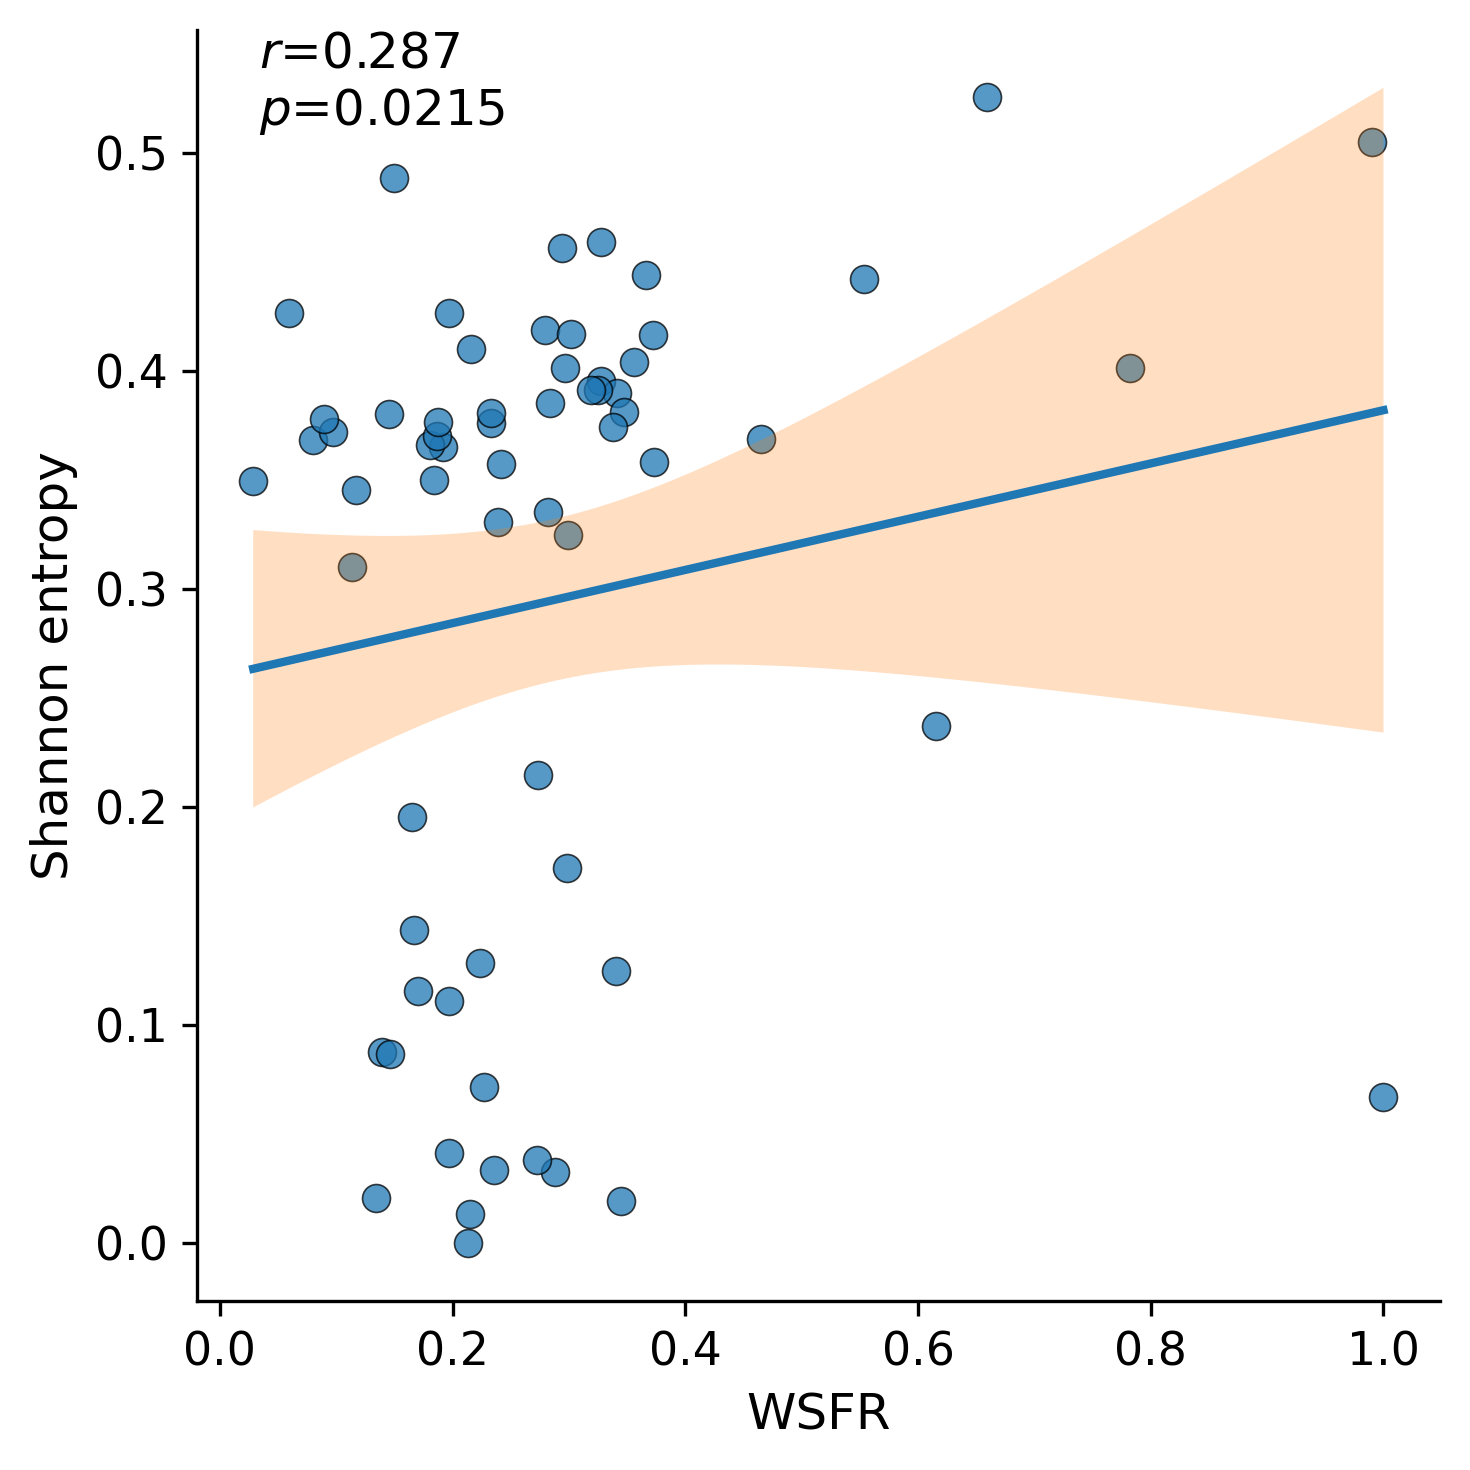

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

x=df_combined["WSFR"].values
y=df_combined["Shannon_Entropy"].values
r,p=stats.spearmanr(x,y)

fig,ax=plt.subplots(figsize=(5,5),dpi=300)
ax.scatter(x,y,s=45,alpha=0.75,edgecolor="black",linewidth=0.4)

coef=np.polyfit(x,y,1)
xx=np.linspace(x.min(),x.max(),200)
yy=np.polyval(coef,xx)

res=y-np.polyval(coef,x)
n=len(x)
se=np.sqrt(np.sum(res**2)/(n-2))
ci=1.96*se*np.sqrt(1/n+(xx-x.mean())**2/np.sum((x-x.mean())**2))

ax.plot(xx,yy,linewidth=2)
ax.fill_between(xx,yy-ci,yy+ci,alpha=0.25)

ax.text(0.05,1,f"$r$={r:.3f}\n$p$={p:.4f}",transform=ax.transAxes,va="top",fontsize=12)
ax.set_xlabel("WSFR",fontsize=12)
ax.set_ylabel("Shannon entropy",fontsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.savefig("WSFR_vs_Shannon_Entropy.png",dpi=600,bbox_inches="tight",transparent=False)
plt.show()

Partial correlation: r=0.291, p=0.0197


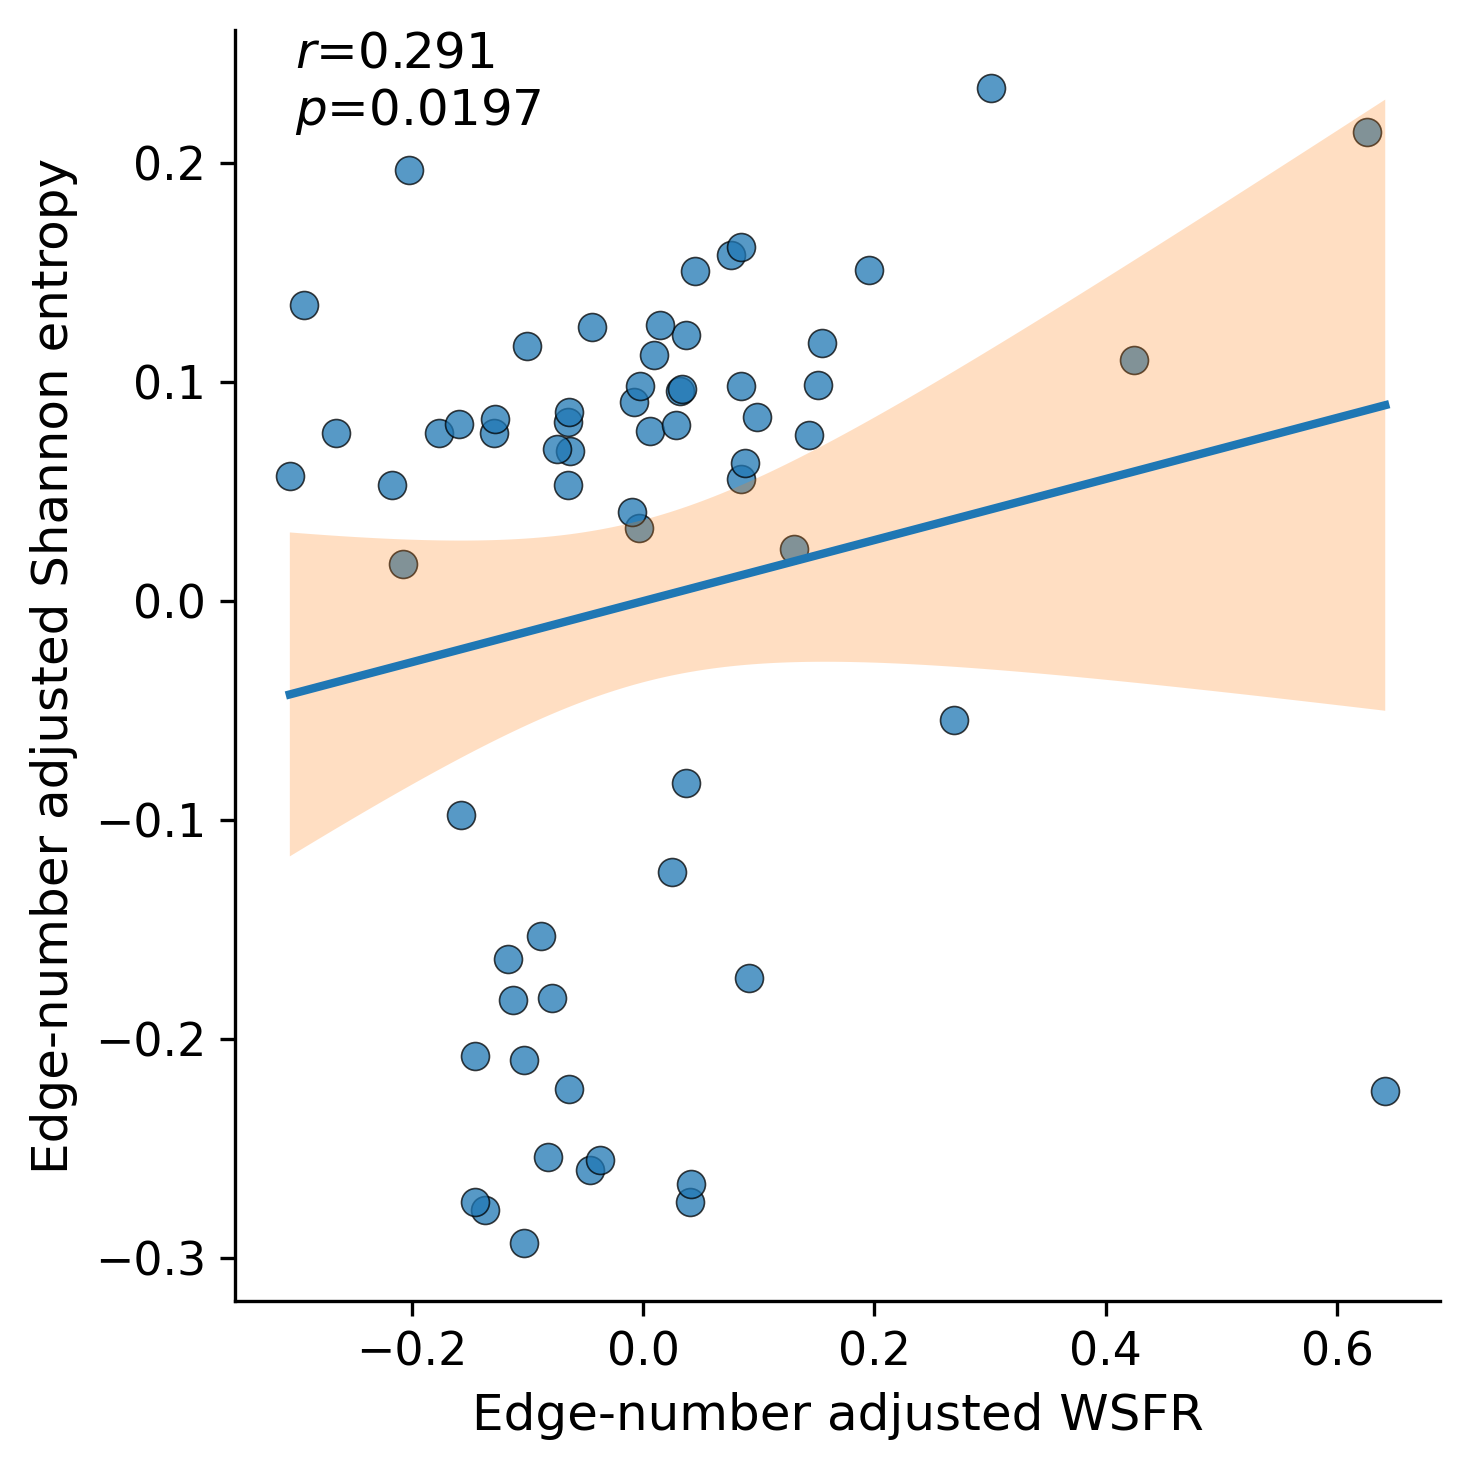

In [14]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "total_nonzero"]
)



def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["WSFR"].values
y = df["Shannon_Entropy"].values
z = df["total_nonzero"].values


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = spearmanr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 1,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Edge-number adjusted WSFR", fontsize=12)
ax.set_ylabel("Edge-number adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Partial correlation: r=0.284, p=0.0229


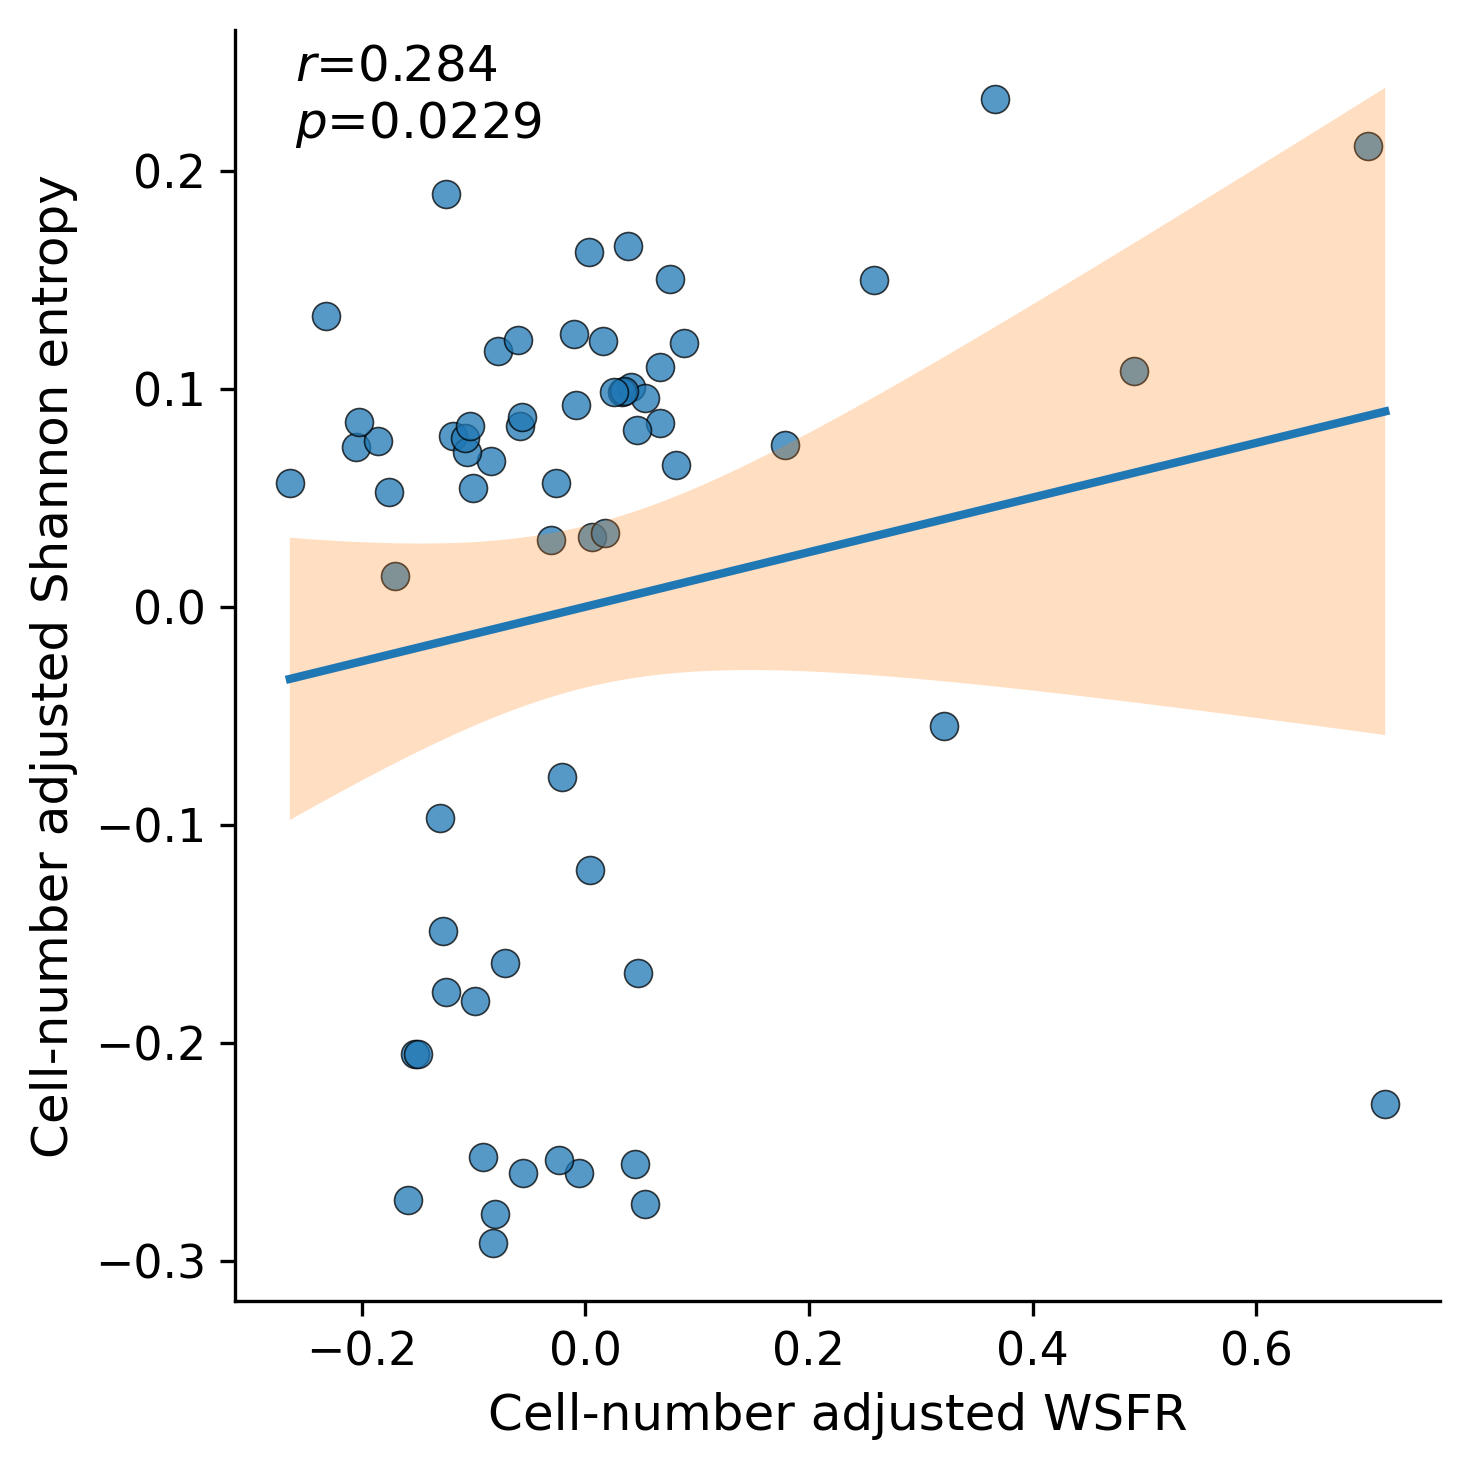

In [15]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "cell_number"]
)



def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["WSFR"].values
y = df["Shannon_Entropy"].values
z = df["cell_number"].values


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = spearmanr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 0.99,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Cell-number adjusted WSFR", fontsize=12)
ax.set_ylabel("Cell-number adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy_cell-number.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Partial correlation: r=0.301, p=0.0157


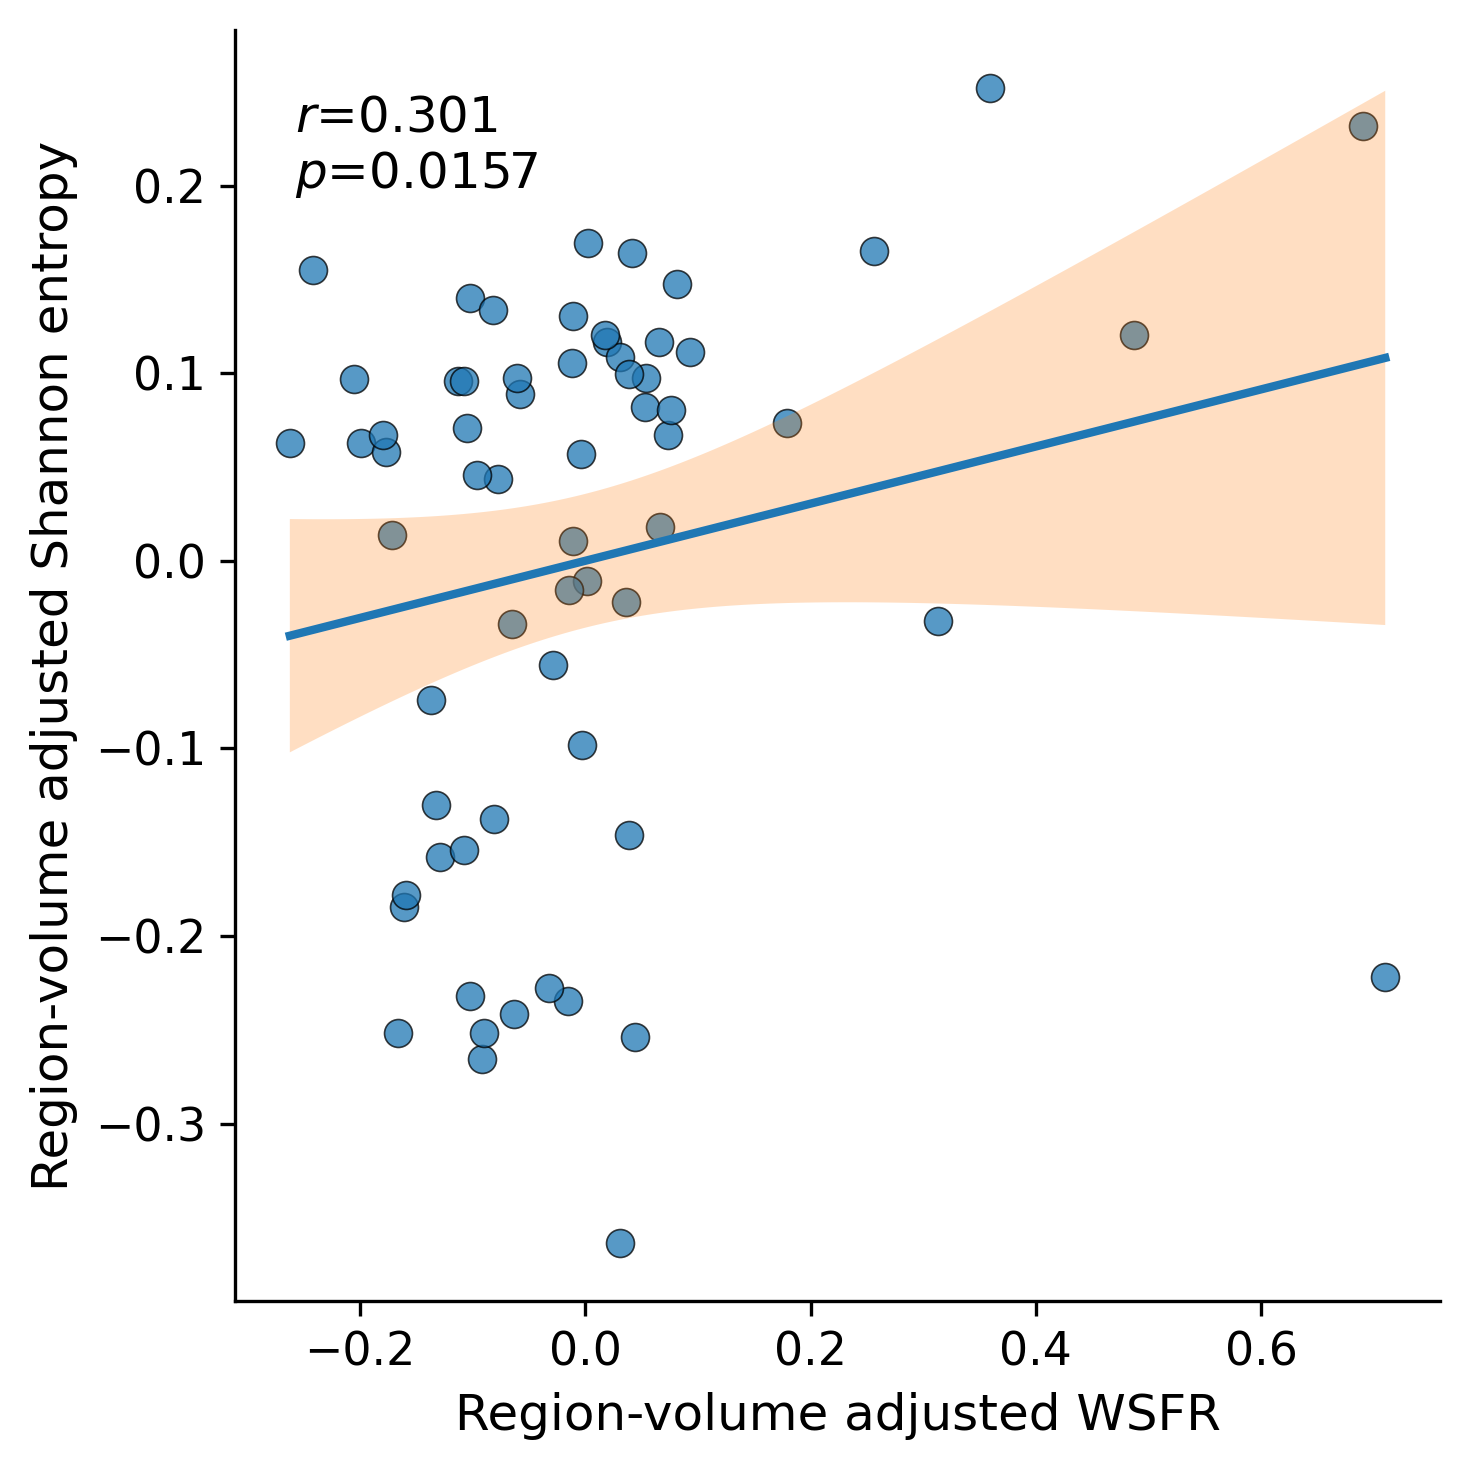

In [16]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import matplotlib.pyplot as plt


df = df_combined.copy()

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(
    subset=["WSFR", "Shannon_Entropy", "volume"]
)


def residualize(y, z):
    z = np.column_stack([np.ones(len(z)),z])

    beta = np.linalg.lstsq(z,y,rcond=None)[0]

    y_pred = z @ beta

    return y - y_pred


x = df["WSFR"].values
y = df["Shannon_Entropy"].values
z = df["volume"].values


x_res = residualize(x,z)

y_res = residualize(y,z)


r, p = spearmanr(x_res,y_res)

print(f"Partial correlation: r={r:.3f}, p={p:.4f}")


# =========================
# plot
# =========================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5,5), dpi=300)

ax.scatter(x_res, y_res, s=45, alpha=0.75, edgecolor="black", linewidth=0.4)

coef = np.polyfit(x_res, y_res, 1)
xx = np.linspace(x_res.min(), x_res.max(), 200)
yy = np.polyval(coef, xx)

residuals = y_res - np.polyval(coef, x_res)
n = len(x_res)
s_err = np.sqrt(np.sum(residuals**2)/(n-2))
x_mean = np.mean(x_res)
sxx = np.sum((x_res-x_mean)**2)

ci = 1.96*s_err*np.sqrt(1/n+(xx-x_mean)**2/sxx)

ax.plot(xx, yy, linewidth=2)
ax.fill_between(xx, yy-ci, yy+ci, alpha=0.25)

ax.text(
    0.05, 0.95,
    f"$r$={r:.3f}\n$p$={p:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=12
)

ax.set_xlabel("Region-volume adjusted WSFR", fontsize=12)
ax.set_ylabel("Region-volume adjusted Shannon entropy", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(labelsize=11)

plt.tight_layout()

plt.savefig(
    "partial_correlation_WSFR_entropy_region-volume.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Bootstrap mean r: 0.2849283266685666
95% CI: [0.03828287 0.51673267]


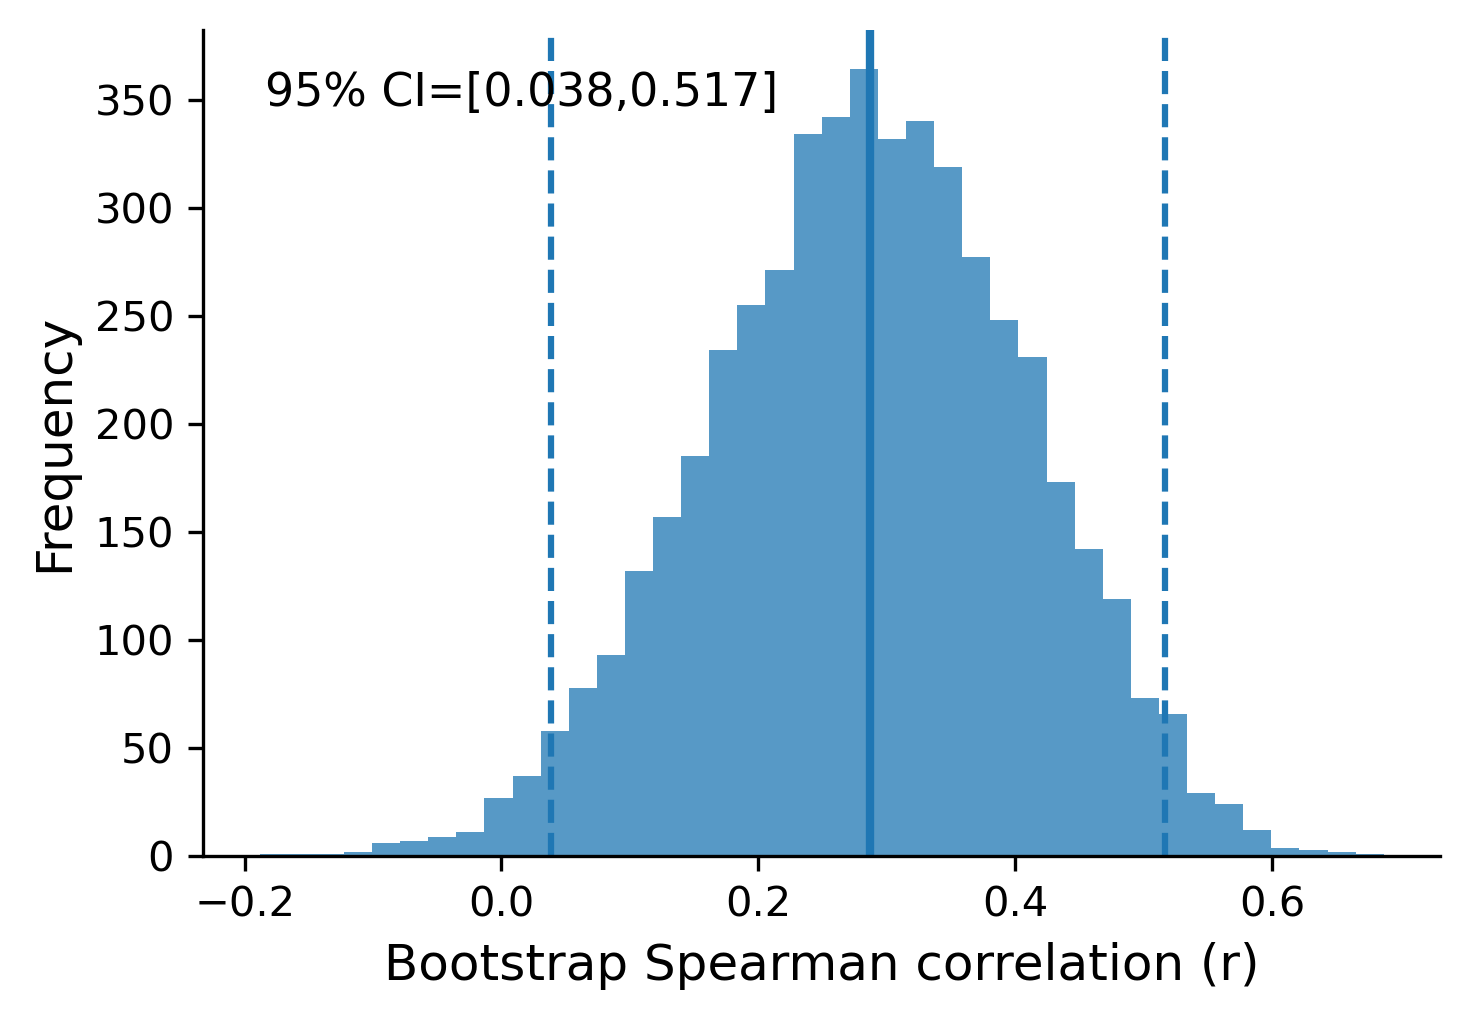

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

np.random.seed(42)

x=df_combined["WSFR"].values
y=df_combined["Shannon_Entropy"].values

r_boot=[]
for i in range(5000):
    idx=np.random.choice(len(x),len(x),replace=True)
    r_boot.append(spearmanr(x[idx],y[idx])[0])

r_boot=np.array(r_boot)
obs_r=spearmanr(x,y)[0]
ci=np.percentile(r_boot,[2.5,97.5])

print("Bootstrap mean r:",r_boot.mean())
print("95% CI:",ci)

fig,ax=plt.subplots(figsize=(5,3.5),dpi=300)

ax.hist(r_boot,bins=40,alpha=0.75)
ax.axvline(obs_r,linewidth=2,label=f"Observed r={obs_r:.3f}")
ax.axvline(ci[0],ls="--",linewidth=1.5)
ax.axvline(ci[1],ls="--",linewidth=1.5)

ax.text(
    0.05,0.95,
    f"95% CI=[{ci[0]:.3f},{ci[1]:.3f}]",
    transform=ax.transAxes,
    va="top",
    fontsize=11
)

ax.set_xlabel("Bootstrap Spearman correlation (r)",fontsize=12)
ax.set_ylabel("Frequency",fontsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    "bootstrap_WSFR_entropy.png",
    dpi=600,
    bbox_inches="tight",
    transparent=False
)
plt.show()

original r: 0.2870421245421245
jackknife range: 0.25528033794162824 0.3360695084485407


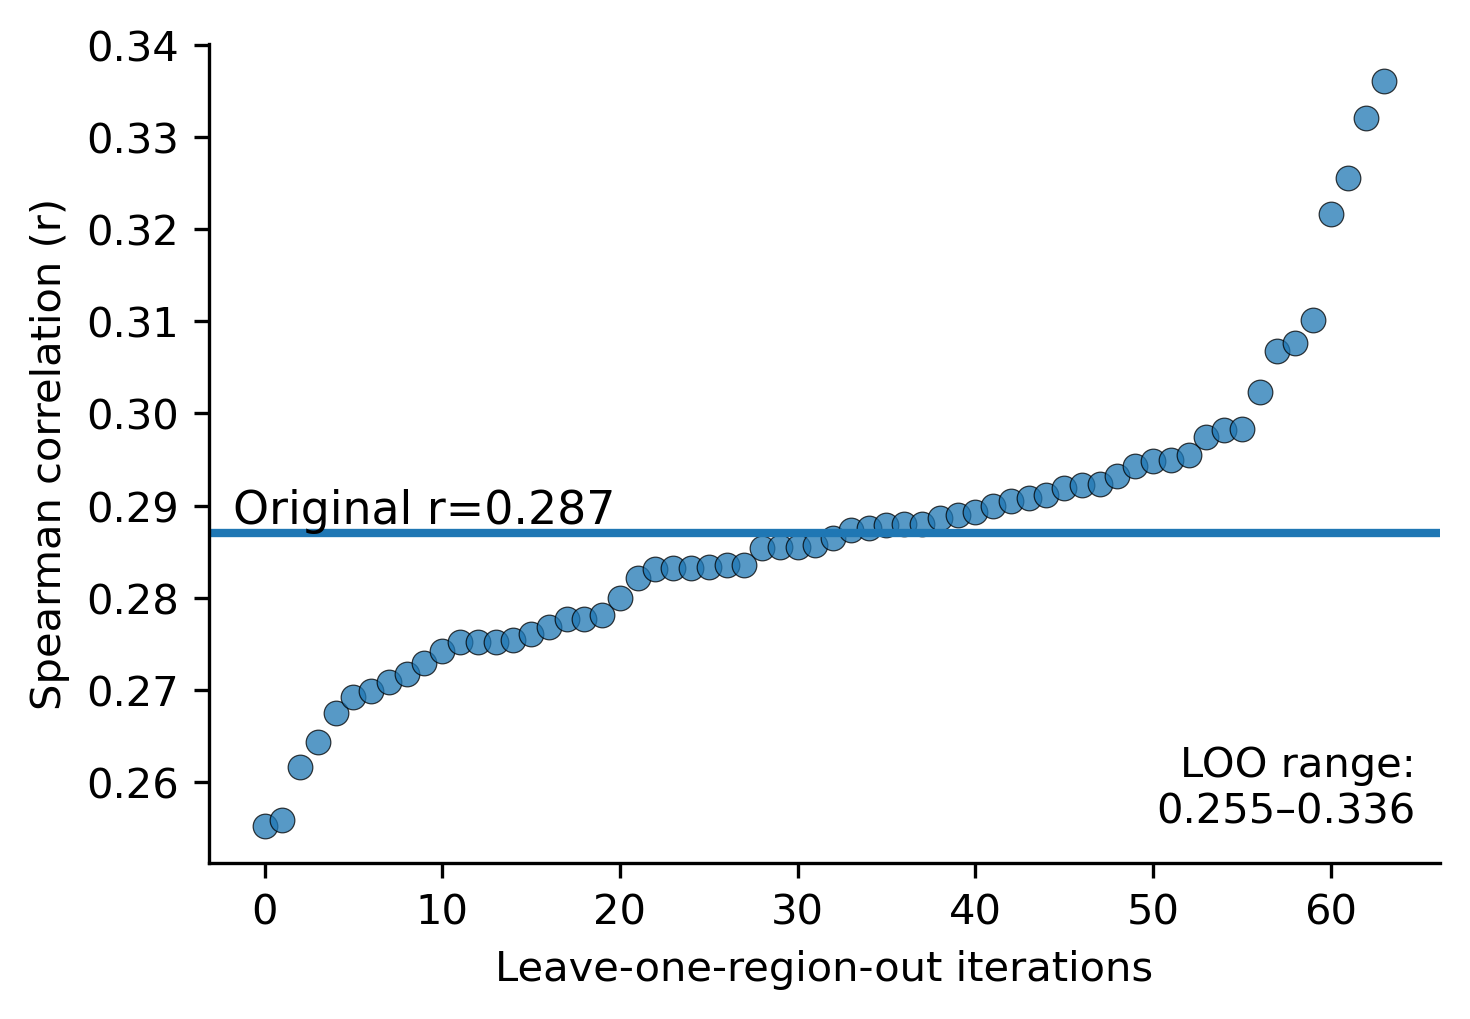

In [18]:
from scipy.stats import spearmanr
import numpy as np

x = df_combined["WSFR"].values
y = df_combined["Shannon_Entropy"].values

r_values=[]

for i in range(len(x)):

    mask=np.ones(len(x),dtype=bool)
    mask[i]=False

    r,p=spearmanr(
        x[mask],
        y[mask]
    )

    r_values.append(r)


print("original r:",spearmanr(x,y)[0])

print("jackknife range:",min(r_values),max(r_values))

r_values=np.array(r_values)
r_obs=spearmanr(x,y)[0]
r_sort=np.sort(r_values)

fig,ax=plt.subplots(figsize=(5,3.5),dpi=300)

ax.scatter(np.arange(len(r_sort)),r_sort,s=35,alpha=0.75,edgecolor="black",linewidth=0.3)
ax.axhline(r_obs,linewidth=2)

ax.text(0.02,r_obs,f"Original r={r_obs:.3f}",transform=ax.get_yaxis_transform(),va="bottom",fontsize=11)
ax.text(0.98,0.05,f"LOO range:\n{r_sort.min():.3f}–{r_sort.max():.3f}",
        transform=ax.transAxes,ha="right",fontsize=10)

ax.set(xlabel="Leave-one-region-out iterations",ylabel="Spearman correlation (r)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("jackknife_WSFR_entropy.png",dpi=600,bbox_inches="tight",transparent=False)
plt.show()